# Chapter 5 — 프로토콜 취약점과 트래픽 분석 (실습)

## 실습 목표
1. 합성 SYN Flood 트래픽에서 SYN/ACK 비율 비정상을 탐지한다.
2. ARP 패킷에서 같은 IP 에 다중 MAC 응답을 검출한다.
3. DNS 트래픽에서 응답 수가 쿼리 수보다 많은 도메인을 찾는다.
4. 위 세 탐지 함수를 작은 라이브러리로 패키징한다.



In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q scapy cryptography   # cryptography: scapy TLS 레이어용

In [2]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from pathlib import Path
from scapy.all import (
    Ether, IP, TCP, UDP, ARP, DNS, DNSQR, DNSRR, wrpcap, rdpcap, Raw
)

---
## Step 1. 합성 SYN Flood PCAP 만들기 + 탐지

In [4]:
# 정상 트래픽 200개 + SYN Flood 800개 혼합
rng = np.random.default_rng(42)
victim_ip = '10.0.0.100'
packets = []

# 정상 완전 3-way handshake 100세트 (300 packets)
for _ in range(100):
    src = f'192.168.1.{rng.integers(1, 50)}'
    sport = int(rng.integers(20000, 60000))
    packets.append(IP(src=src, dst=victim_ip)/TCP(sport=sport, dport=80, flags='S'))
    packets.append(IP(src=victim_ip, dst=src)/TCP(sport=80, dport=sport, flags='SA'))
    packets.append(IP(src=src, dst=victim_ip)/TCP(sport=sport, dport=80, flags='A'))

# SYN Flood (응답 없는 SYN) 700개
for _ in range(700):
    src = f'{rng.integers(1,255)}.{rng.integers(0,255)}.{rng.integers(0,255)}.{rng.integers(1,255)}'
    sport = int(rng.integers(1024, 65535))
    packets.append(IP(src=src, dst=victim_ip)/TCP(sport=sport, dport=80, flags='S'))

rng.shuffle(packets)
OUT = Path.cwd() / 'syn_flood.pcap'
wrpcap(str(OUT), packets)
print(f'생성됨: {OUT.name} ({len(packets)} packets)')

생성됨: syn_flood.pcap (1000 packets)


In [5]:
def detect_syn_flood(pcap_path: str, dst_ip: str, threshold: float = 5.0):
    """SYN / (SYN+ACK) 비율이 threshold 보다 크면 SYN Flood 의심 반환."""
    pkts = rdpcap(pcap_path)
    n_syn, n_synack = 0, 0
    for p in pkts:
        if IP not in p or TCP not in p:
            continue
        flags = str(p[TCP].flags)
        if p[IP].dst == dst_ip and 'S' in flags and 'A' not in flags:
            n_syn += 1
        if p[IP].src == dst_ip and 'S' in flags and 'A' in flags:
            n_synack += 1
    ratio = n_syn / max(n_synack, 1)
    return {'syn': n_syn, 'syn_ack': n_synack, 'ratio': ratio, 'flood': ratio > threshold}

result = detect_syn_flood(str(OUT), victim_ip)
print(result)

{'syn': 800, 'syn_ack': 100, 'ratio': 8.0, 'flood': True}


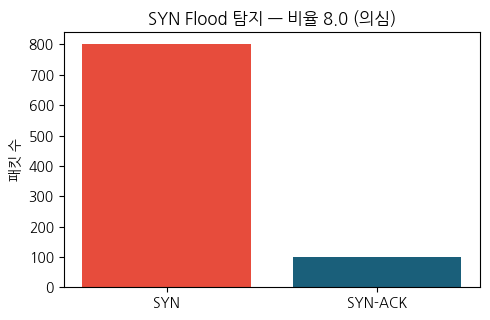

In [6]:
# SYN Flood 시각화 — 정상은 SYN ≈ SYN-ACK, 플러드는 SYN 폭증
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5, 3.3))
ax.bar(['SYN', 'SYN-ACK'], [result['syn'], result['syn_ack']], color=['#e74c3c', '#1a5f7a'])
ax.set_title(f"SYN Flood 탐지 — 비율 {result['ratio']:.1f} ({'의심' if result['flood'] else '정상'})")
ax.set_ylabel('패킷 수')
plt.tight_layout(); plt.show()

관찰: 정상은 1:1 비율이어야 하지만, SYN Flood 포함된 PCAP 는 SYN/SYN+ACK 비율이 크게 치우친다.

---
## Step 2. 합성 ARP Spoof + 탐지

In [7]:
arp_pkts = []
# 정상 ARP 응답: 10.0.0.1 = AA:AA:AA:AA:AA:AA (Gateway)
for _ in range(20):
    arp_pkts.append(Ether()/ARP(op=2, hwsrc='AA:AA:AA:AA:AA:AA', psrc='10.0.0.1'))
# 공격자 위조 ARP: 10.0.0.1 = EE:EE:EE:EE:EE:EE
for _ in range(15):
    arp_pkts.append(Ether()/ARP(op=2, hwsrc='EE:EE:EE:EE:EE:EE', psrc='10.0.0.1'))
# 정상 ARP 응답: 10.0.0.50 = BB:BB:BB:BB:BB:BB
for _ in range(5):
    arp_pkts.append(Ether()/ARP(op=2, hwsrc='BB:BB:BB:BB:BB:BB', psrc='10.0.0.50'))

rng.shuffle(arp_pkts)
ARP_OUT = Path.cwd() / 'arp_spoof.pcap'
wrpcap(str(ARP_OUT), arp_pkts)

def detect_arp_spoof(pcap_path: str):
    """같은 IP 에 여러 MAC 응답이 있으면 의심 IP 와 MAC 목록 반환."""
    ip_to_macs = defaultdict(set)
    for p in rdpcap(pcap_path):
        if ARP in p and p[ARP].op == 2:  # op=2 is reply
            ip_to_macs[p[ARP].psrc].add(p[ARP].hwsrc)
    return {ip: list(macs) for ip, macs in ip_to_macs.items() if len(macs) > 1}

suspects = detect_arp_spoof(str(ARP_OUT))
print('ARP Spoof 의심:')
for ip, macs in suspects.items():
    print(f'  {ip} -> {macs}')

ARP Spoof 의심:
  10.0.0.1 -> ['ee:ee:ee:ee:ee:ee', 'aa:aa:aa:aa:aa:aa']


---
## Step 3. 합성 DNS Poison + 탐지

In [8]:
dns_pkts = []
# 정상: 1 쿼리 -> 1 응답
for i, dom in enumerate(['example.com', 'google.com', 'github.com'] * 5):
    tid = 0x1000 + i
    dns_pkts.append(IP()/UDP(dport=53)/DNS(id=tid, qr=0, qd=DNSQR(qname=dom)))
    dns_pkts.append(IP()/UDP(sport=53)/DNS(id=tid, qr=1, qd=DNSQR(qname=dom),
                                            an=DNSRR(rrname=dom, rdata='1.2.3.4')))
# 공격자: bank.com 1 쿼리에 3개 위조 응답 (서로 다른 IP)
dns_pkts.append(IP()/UDP(dport=53)/DNS(id=0x9999, qr=0, qd=DNSQR(qname='bank.com')))
for fake_ip in ['6.6.6.6', '7.7.7.7', '8.8.8.8']:
    dns_pkts.append(IP()/UDP(sport=53)/DNS(id=0x9999, qr=1, qd=DNSQR(qname='bank.com'),
                                            an=DNSRR(rrname='bank.com', rdata=fake_ip)))

rng.shuffle(dns_pkts)
DNS_OUT = Path.cwd() / 'dns_poison.pcap'
wrpcap(str(DNS_OUT), dns_pkts)

def detect_dns_poison(pcap_path: str):
    """같은 도메인 쿼리에 2개 이상 응답이 오면 의심 반환."""
    queries = defaultdict(int)
    responses = defaultdict(int)
    for p in rdpcap(pcap_path):
        if DNS not in p:
            continue
        d = p[DNS]
        if d.qd is None:
            continue
        qname = d.qd.qname.decode(errors='replace').rstrip('.')
        if d.qr == 0:
            queries[qname] += 1
        else:
            responses[qname] += 1
    suspects = {dom: (responses[dom], queries.get(dom, 0))
                for dom in responses if responses[dom] > queries.get(dom, 0)}
    return suspects

suspects = detect_dns_poison(str(DNS_OUT))
print('DNS Poison 의심 도메인:')
for dom, (n_resp, n_query) in suspects.items():
    print(f'  {dom}: {n_resp} responses / {n_query} queries')

DNS Poison 의심 도메인:
  bank.com: 3 responses / 1 queries


---
## Step 4. TLS ClientHello 와 JA3 핑거프린트

본문 §5.4.3 의 JA3 를 직접 계산한다. JA3 는 TLS 핸드셰이크의 **첫 메시지(ClientHello)** 에 담긴
TLS 버전·암호군·확장·타원곡선·포인트 형식을 순서대로 이어 붙인 뒤 MD5 로 해시한 값이다.
암호화가 시작되기 **전에** 평문으로 오가는 메시지라 **복호화 없이** 계산할 수 있다.

같은 사이트(`www.example.com`)에 접속하는 두 클라이언트를 만들어 JA3 를 비교한다.

In [9]:
from scapy.all import load_layer
load_layer('tls')
from scapy.layers.tls.handshake import TLSClientHello
from scapy.layers.tls.extensions import (TLS_Ext_ServerName, ServerName,
                                         TLS_Ext_SupportedGroups, TLS_Ext_SupportedPointFormat)
import hashlib

# GREASE(0x0a0a 등)는 브라우저가 무작위로 끼워 넣는 값이라 JA3 계산에서 제외한다
GREASE = {0x0a0a, 0x1a1a, 0x2a2a, 0x3a3a, 0x4a4a, 0x5a5a, 0x6a6a, 0x7a7a,
          0x8a8a, 0x9a9a, 0xaaaa, 0xbaba, 0xcaca, 0xdada, 0xeaea, 0xfafa}

def build_client_hello(version, ciphers, groups, point_formats, sni):
    exts = [TLS_Ext_ServerName(servernames=[ServerName(servername=sni)]),
            TLS_Ext_SupportedGroups(groups=groups),
            TLS_Ext_SupportedPointFormat(ecpl=point_formats)]
    return TLSClientHello(version=version, ciphers=ciphers, ext=exts)

def ja3_fingerprint(hello_bytes: bytes):
    """ClientHello 바이트에서 JA3 문자열과 MD5 해시를 계산한다."""
    h = TLSClientHello(hello_bytes)                      # 바이트에서 다시 파싱 (실제 캡처와 같은 경로)
    ciphers = [c for c in h.ciphers if c not in GREASE]
    exts    = [e.type for e in (h.ext or []) if e.type not in GREASE]
    groups, point_formats = [], []
    for e in (h.ext or []):
        if isinstance(e, TLS_Ext_SupportedGroups):
            groups = [g for g in e.groups if g not in GREASE]
        if isinstance(e, TLS_Ext_SupportedPointFormat):
            point_formats = list(e.ecpl)
    ja3_str = ','.join([str(h.version),
                        '-'.join(map(str, ciphers)),
                        '-'.join(map(str, exts)),
                        '-'.join(map(str, groups)),
                        '-'.join(map(str, point_formats))])
    return ja3_str, hashlib.md5(ja3_str.encode()).hexdigest()

# 최신 브라우저: TLS 1.3 AEAD 암호군 + ECDHE-GCM, x25519 우선
browser = build_client_hello(0x0303,
    [0x1301, 0x1302, 0x1303, 0xc02b, 0xc02f, 0xc02c, 0xc030],
    [0x001d, 0x0017, 0x0018], [0], 'www.example.com')
# 오래된 라이브러리 기반 자동화 도구: 구형 RSA·CBC 암호군만 제시
tool = build_client_hello(0x0303,
    [0x0035, 0x002f, 0x000a],
    [0x0017], [0], 'www.example.com')

ja3_table = []
for name, hello in [('browser', browser), ('tool', tool)]:
    ja3_str, digest = ja3_fingerprint(bytes(hello))
    ja3_table.append({'client': name, 'sni': 'www.example.com', 'ja3': digest, 'ja3_string': ja3_str})
    print(f'{name:<8} JA3 = {digest}')
    print(f'{"":<8} 문자열 = {ja3_str}')

pd.DataFrame(ja3_table)[['client', 'sni', 'ja3']]

browser  JA3 = c0d9b4569df049e63b2b1bd4e645b69c
         문자열 = 771,4865-4866-4867-49195-49199-49196-49200,0-10-11,29-23-24,0
tool     JA3 = 7f98798dd6c16c54a98436abd7f0b884
         문자열 = 771,53-47-10,0-10-11,23,0


,client,sni,ja3
0,browser,www.example.com,c0d9b4569df049e63b2b1bd4e645b69c
1,tool,www.example.com,7f98798dd6c16c54a98436abd7f0b884


---
## Step 5. 작은 탐지 도구 패키징

In [10]:
def analyze_pcap(pcap_path: str, dst_ip: str = '10.0.0.100') -> dict:
    return {
        'syn_flood': detect_syn_flood(pcap_path, dst_ip),
        'arp_spoof': detect_arp_spoof(pcap_path),
        'dns_poison': detect_dns_poison(pcap_path),
    }

# 세 PCAP 모두 분석
for path in [str(Path.cwd() / n) for n in ['syn_flood.pcap', 'arp_spoof.pcap', 'dns_poison.pcap']]:
    print(f'\n=== {Path(path).name} ===')
    for k, v in analyze_pcap(path).items():
        print(f'  {k}: {v}')


=== syn_flood.pcap ===


  syn_flood: {'syn': 800, 'syn_ack': 100, 'ratio': 8.0, 'flood': True}
  arp_spoof: {}
  dns_poison: {}

=== arp_spoof.pcap ===


  syn_flood: {'syn': 0, 'syn_ack': 0, 'ratio': 0.0, 'flood': False}
  arp_spoof: {'10.0.0.1': ['ee:ee:ee:ee:ee:ee', 'aa:aa:aa:aa:aa:aa']}
  dns_poison: {}

=== dns_poison.pcap ===
  syn_flood: {'syn': 0, 'syn_ack': 0, 'ratio': 0.0, 'flood': False}
  arp_spoof: {}
  dns_poison: {'bank.com': (3, 1)}


---
## 정리

- SYN/SYN+ACK 비율, IP-MAC 매핑, DNS 응답/쿼리 비율 — 단순한 통계지표만으로도 1차 탐지가 가능하다.
- TLS 는 복호화하지 않아도 ClientHello 로 클라이언트를 식별할 수 있다(JA3). 목적지가 같아도 소프트웨어가 다르면 해시가 달라진다.
- 이런 룰 기반 탐지는 빠르고 해석 가능하지만, 임계값 우회·노이즈에 취약하다.
- 다음 챕터에서는 PCAP·NetFlow·Zeek 의 형식을 비교하고, 더 풍부한 feature 를 추출하는 파이프라인을 만든다.